# Experiment 018: analysis plots

Six figures summarise the seed 1 continuation from step 500 to step 1000.
The 500-step comparison includes all three 0.5B seeds. Base logprob accuracy is
used only as a probe reference, not as a training ceiling. Experiment 018 extends
one previously weak seed, so it does not show that every seed or scale benefits
from 1000 steps.

In [1]:
import json, os, sys
ROOT = '..' if os.path.basename(os.getcwd()) == 'notebooks' else '.'
sys.path.insert(0, os.path.abspath(ROOT))
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from analysis.stats import _read_preds, align_pred_rows
from data.subjects import tier_of, TIERS

R = os.path.join(ROOT, 'results')
FIGDIR = os.path.join(ROOT, 'analysis', 'figures', '018_1')
os.makedirs(FIGDIR, exist_ok=True)

def overall(path):
    rows = _read_preds(path)
    return sum(r['correct'] for r in rows) / len(rows)

def tier_accs(path):
    rows = _read_preds(path)
    out = {}
    for tier in TIERS:
        values = [r['correct'] for r in rows if tier_of(r['subject']) == tier]
        out[tier] = sum(values) / len(values)
    return out

# load the saved endpoints used in the figures
path_500 = f'{R}/006_COLAB_FULL_B05_sft_grpo_seed1/grpo_preds.jsonl'
path_1000 = f'{R}/018_ext_B05_seed1_step1000/grpo_preds.jsonl'
rows_500, rows_1000 = align_pred_rows(_read_preds(path_500), _read_preds(path_1000))
summary = json.load(open(f'{R}/018_ext_B05_seed1_step1000/comparison_summary.json'))
s1_500 = overall(path_500)
s1_1000 = overall(path_1000)
s0 = overall(f'{R}/006_COLAB_FULL_B05_sft_grpo_seed0/grpo_preds.jsonl')
s2 = overall(f'{R}/006_COLAB_FULL_B05_sft_grpo_seed2/grpo_preds.jsonl')
mcsft = sum(overall(f'{R}/007_p8_COLAB_FULL_B05_sft_only_seed{s}/sft_preds.jsonl') for s in (0, 1, 2)) / 3
probe_05 = overall(f'{R}/base_evals/006_COLAB_FULL_B05/base_logprob_preds.jsonl')
selected_450 = overall(f'{R}/017_selector_B05_seed1_step450/grpo_preds.jsonl')
print(f'0.5b: seed1 {s1_500:.3f} -> {s1_1000:.3f}, siblings {s0:.3f}/{s2:.3f}, mc-sft {mcsft:.3f}, probe {probe_05:.3f}')

0.5b: seed1 0.315 -> 0.515, siblings 0.462/0.506, mc-sft 0.534, probe 0.567


## Reward and learning-rate trajectory

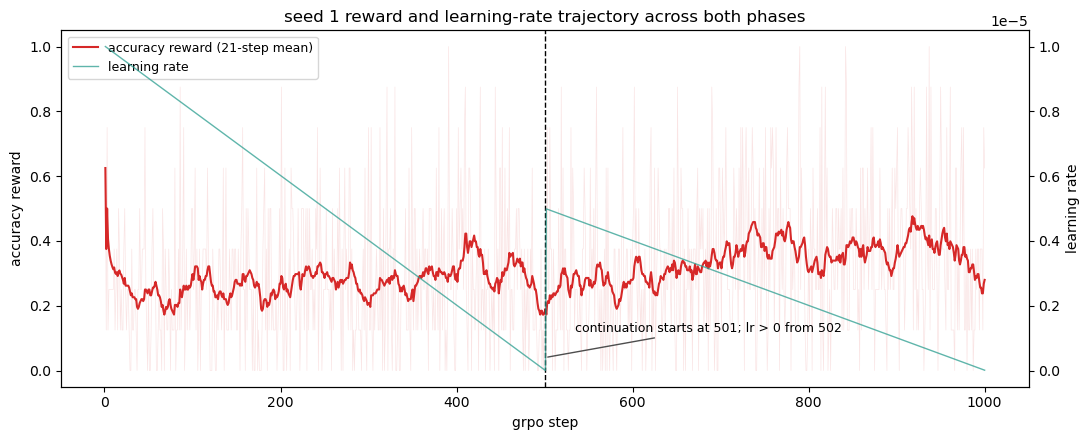

In [2]:
# plot the reward and learning-rate trajectories across both phases
curve = json.load(open(f'{R}/018_ext_B05_seed1_step1000/combined_reward_curve.json'))
steps = sorted(int(s) for s in curve)
reward = [curve[str(s)] for s in steps]
window = 21
smooth = [sum(reward[max(0, i-window+1):i+1]) / len(reward[max(0, i-window+1):i+1]) for i in range(len(reward))]

trainlog_500 = json.load(open(f'{R}/006_COLAB_FULL_B05_sft_grpo_seed1/grpo_trainlog.json'))
trainlog_1000 = json.load(open(f'{R}/018_ext_B05_seed1_step1000/grpo_trainlog.json'))
learning_rate = {}
for entry in trainlog_500 + trainlog_1000:
    if 'learning_rate' in entry and 'step' in entry:
        learning_rate.setdefault(entry['step'], entry['learning_rate'])
lr_steps = sorted(learning_rate)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(steps, reward, color='#d62828', lw=0.5, alpha=0.12)
ax.plot(steps, smooth, color='#d62828', lw=1.5, label='accuracy reward (21-step mean)')
ax.axvline(500.5, color='k', ls='--', lw=1)
ax.annotate('continuation starts at 501; lr > 0 from 502', xy=(500.5, 0.04),
            xytext=(535, 0.12), arrowprops=dict(arrowstyle='-', color='0.3'), fontsize=9)
ax.set_xlabel('grpo step')
ax.set_ylabel('accuracy reward')
ax2 = ax.twinx()
ax2.plot(lr_steps, [learning_rate[s] for s in lr_steps], color='#2a9d8f', lw=1, alpha=0.75, label='learning rate')
ax2.set_ylabel('learning rate')
ax.set_title('seed 1 reward and learning-rate trajectory across both phases')
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper left', fontsize=9)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig_recovery_curve.png'), dpi=200, bbox_inches='tight')
plt.show()

## 0.5B endpoints

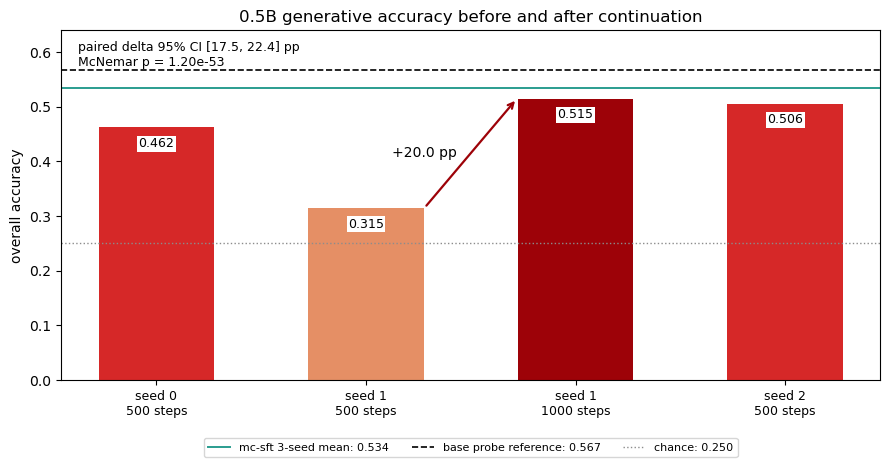

In [3]:
# compare the 0.5b generative endpoints
fig, ax = plt.subplots(figsize=(9, 4.8))
x = [0, 1, 2, 3]
names = ['seed 0\n500 steps', 'seed 1\n500 steps', 'seed 1\n1000 steps', 'seed 2\n500 steps']
endpoints = [s0, s1_500, s1_1000, s2]
colours = ['#d62828', '#e58f65', '#9d0208', '#d62828']
bars = ax.bar(x, endpoints, 0.55, color=colours)
for position, value in zip(x, endpoints):
    ax.annotate(f'{value:.3f}', (position, value), xytext=(0, -7),
                textcoords='offset points', ha='center', va='top', fontsize=9,
                bbox=dict(facecolor='white', edgecolor='none', pad=1))
ax.annotate('', xy=(1.72, s1_1000), xytext=(1.28, s1_500),
            arrowprops=dict(arrowstyle='->', lw=1.6, color='#9d0208'))
ax.annotate(f'+{summary["delta"] * 100:.1f} pp', (1.5, (s1_500 + s1_1000) / 2),
            xytext=(-10, 0), textcoords='offset points', ha='right', va='center', fontsize=10)
ax.axhline(mcsft, color='#2a9d8f', lw=1.4, label=f'mc-sft 3-seed mean: {mcsft:.3f}')
ax.axhline(probe_05, color='k', ls='--', lw=1.2, label=f'base probe reference: {probe_05:.3f}')
ax.axhline(0.25, color='0.55', ls=':', lw=1, label='chance: 0.250')
ci_lo, ci_hi = [v * 100 for v in summary['ci']]
ax.text(0.02, 0.97, f'paired delta 95% CI [{ci_lo:.1f}, {ci_hi:.1f}] pp\nMcNemar p = {summary["p"]:.2e}',
        transform=ax.transAxes, va='top', fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(names, fontsize=9)
ax.set_ylabel('overall accuracy')
ax.set_ylim(0, 0.64)
ax.set_title('0.5B generative accuracy before and after continuation')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3, fontsize=8)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig_recovery_endpoints.png'), dpi=200, bbox_inches='tight')
plt.show()

## Generative accuracy relative to the base probe reference

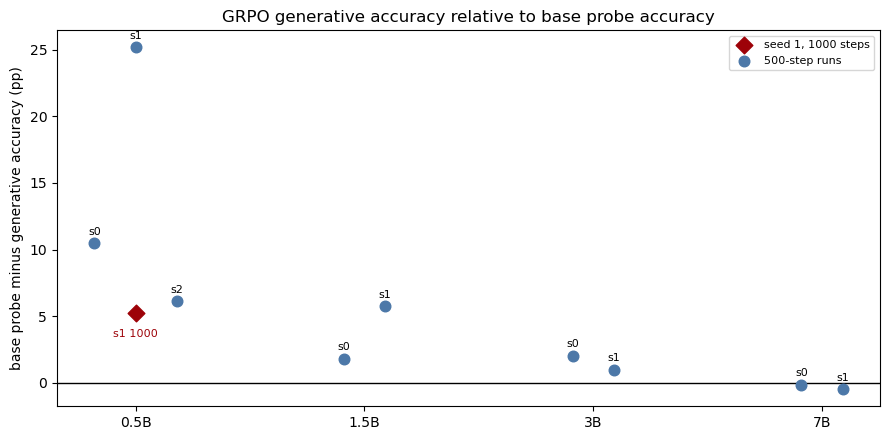

In [4]:
# compare 500-step generative endpoints with the base probe reference
SCALES = {
    '0.5B': ('006_COLAB_FULL_B05', [f'006_COLAB_FULL_B05_sft_grpo_seed{s}' for s in (0, 1, 2)]),
    '1.5B': ('009_COLAB_FULL_B15', [f'009_COLAB_FULL_B15_sft_grpo_seed{s}' for s in (0, 1)]),
    '3B': ('003_COLAB_FULL_B3', [f'003_COLAB_FULL_B3_sft_grpo_seed{s}' for s in (0, 1)]),
    '7B': ('013_COLAB_FULL_B7', [f'013_COLAB_FULL_B7_sft_grpo_seed{s}' for s in (0, 1)]),
}
fig, ax = plt.subplots(figsize=(9, 4.5))
for scale_x, (scale, (base, runs)) in enumerate(SCALES.items()):
    probe = overall(f'{R}/base_evals/{base}/base_logprob_preds.jsonl')
    offsets = [(i - (len(runs) - 1) / 2) * 0.18 for i in range(len(runs))]
    for seed, (run, offset) in enumerate(zip(runs, offsets)):
        gap = (probe - overall(f'{R}/{run}/grpo_preds.jsonl')) * 100
        ax.scatter(scale_x + offset, gap, s=58, color='#4c78a8', zorder=3)
        ax.text(scale_x + offset, gap + 0.65, f's{seed}', ha='center', fontsize=8)
gap_1000 = (probe_05 - s1_1000) * 100
ax.scatter(0, gap_1000, s=72, marker='D', color='#9d0208', zorder=4, label='seed 1, 1000 steps')
ax.text(0, gap_1000 - 1.8, 's1 1000', ha='center', fontsize=8, color='#9d0208')
ax.scatter([], [], s=58, color='#4c78a8', label='500-step runs')
ax.axhline(0, color='k', lw=1)
ax.set_xticks(range(len(SCALES)))
ax.set_xticklabels(SCALES)
ax.set_ylabel('base probe minus generative accuracy (pp)')
ax.set_title('GRPO generative accuracy relative to base probe accuracy')
ax.legend(fontsize=8, loc='upper right')
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig_gap_to_ceiling.png'), dpi=200, bbox_inches='tight')
plt.show()

## Generative and probe accuracy by tier

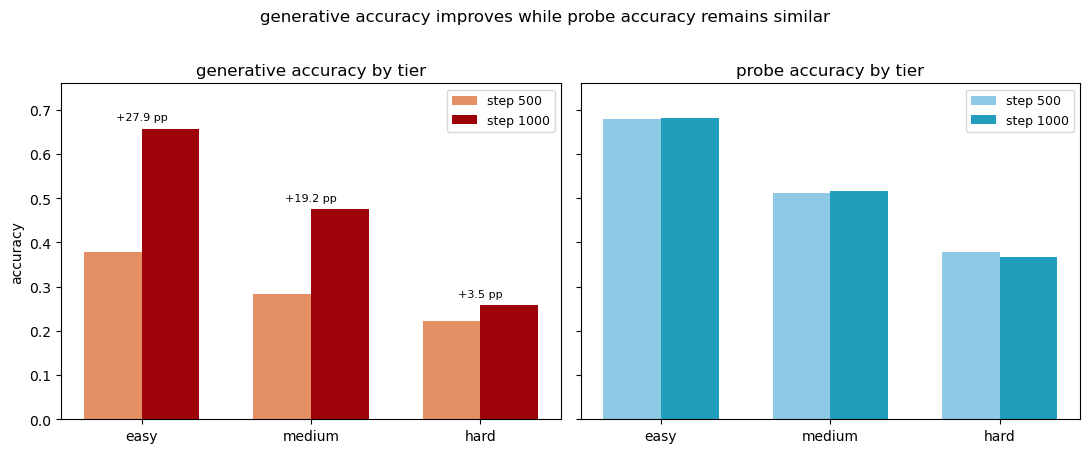

In [5]:
# compare generative and probe accuracy by tier
tier_500 = tier_accs(path_500)
tier_1000 = tier_accs(path_1000)
probe_tier_500 = tier_accs(f'{R}/006_COLAB_FULL_B05_sft_grpo_seed1/grpo_logprob_preds.jsonl')
probe_tier_1000 = tier_accs(f'{R}/018_ext_B05_seed1_step1000/grpo_logprob_preds.jsonl')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
x = list(range(3))
bars_500 = ax1.bar([v - 0.17 for v in x], [tier_500[t] for t in TIERS], 0.34, label='step 500', color='#e58f65')
bars_1000 = ax1.bar([v + 0.17 for v in x], [tier_1000[t] for t in TIERS], 0.34, label='step 1000', color='#9d0208')
for i, tier in enumerate(TIERS):
    delta = (tier_1000[tier] - tier_500[tier]) * 100
    ax1.text(i, max(tier_500[tier], tier_1000[tier]) + 0.018, f'+{delta:.1f} pp', ha='center', fontsize=8)
ax1.set_xticks(x)
ax1.set_xticklabels(TIERS)
ax1.set_ylabel('accuracy')
ax1.set_title('generative accuracy by tier')
ax1.legend(fontsize=9)
ax2.bar([v - 0.17 for v in x], [probe_tier_500[t] for t in TIERS], 0.34, label='step 500', color='#8ecae6')
ax2.bar([v + 0.17 for v in x], [probe_tier_1000[t] for t in TIERS], 0.34, label='step 1000', color='#219ebc')
ax2.set_xticks(x)
ax2.set_xticklabels(TIERS)
ax2.set_title('probe accuracy by tier')
ax2.legend(fontsize=9)
ax1.set_ylim(0, 0.76)
fig.suptitle('generative accuracy improves while probe accuracy remains similar', y=1.02)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig_recovery_decomposition.png'), dpi=200, bbox_inches='tight')
plt.show()

## Paired answer changes

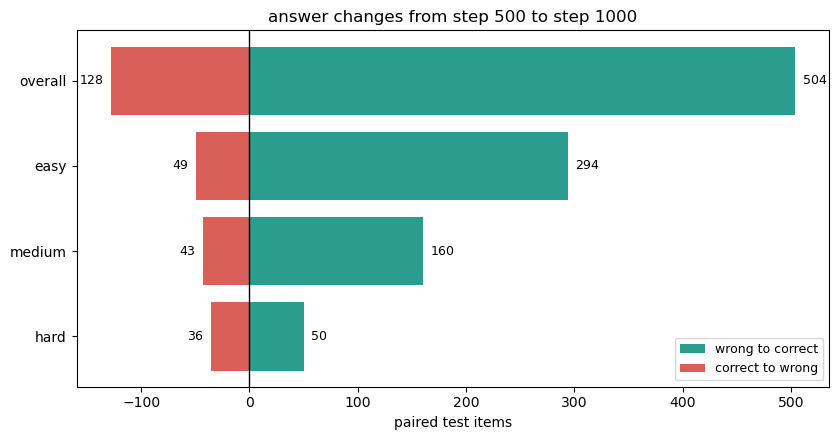

In [6]:
# count the paired answer changes overall and by tier
groups = ['overall'] + list(TIERS)
gained, lost = [], []
for group in groups:
    pairs = [(a, b) for a, b in zip(rows_500, rows_1000)
             if group == 'overall' or tier_of(a['subject']) == group]
    gained.append(sum((not a['correct']) and b['correct'] for a, b in pairs))
    lost.append(sum(a['correct'] and (not b['correct']) for a, b in pairs))

fig, ax = plt.subplots(figsize=(8.5, 4.5))
y = list(range(len(groups)))
ax.barh(y, gained, color='#2a9d8f', label='wrong to correct')
ax.barh(y, [-v for v in lost], color='#d95f59', label='correct to wrong')
for row, (up, down) in enumerate(zip(gained, lost)):
    ax.text(up + 7, row, str(up), va='center', fontsize=9)
    ax.text(-down - 7, row, str(down), va='center', ha='right', fontsize=9)
ax.axvline(0, color='k', lw=1)
ax.set_yticks(y)
ax.set_yticklabels(groups)
ax.invert_yaxis()
ax.set_xlabel('paired test items')
ax.set_title('answer changes from step 500 to step 1000')
ax.legend(fontsize=9, loc='lower right')
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig_paired_transitions.png'), dpi=200, bbox_inches='tight')
plt.show()

## Accuracy change by subject

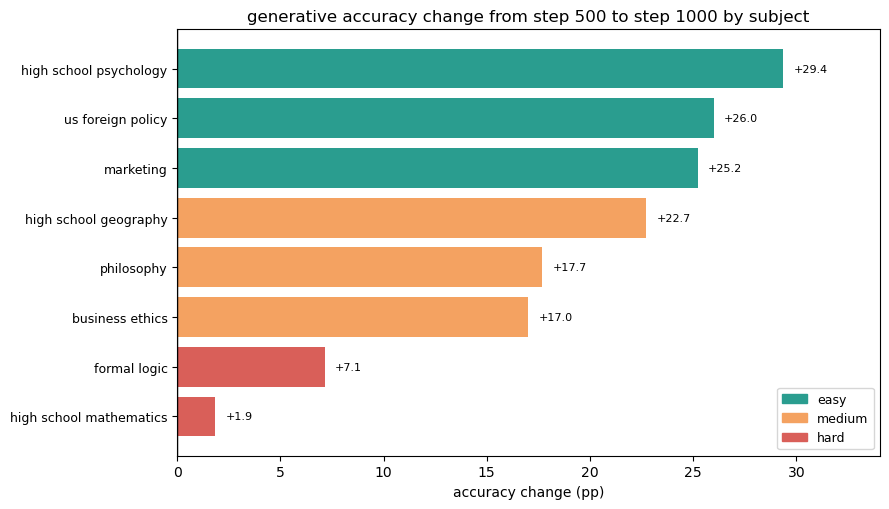

In [7]:
# calculate the paired generative accuracy change for each subject
subject_deltas = []
for subject in sorted({r['subject'] for r in rows_500}):
    before = [r['correct'] for r in rows_500 if r['subject'] == subject]
    after = [r['correct'] for r in rows_1000 if r['subject'] == subject]
    delta = (sum(after) / len(after) - sum(before) / len(before)) * 100
    subject_deltas.append((delta, subject, tier_of(subject)))
subject_deltas.sort()

tier_colours = {'easy': '#2a9d8f', 'medium': '#f4a261', 'hard': '#d95f59'}
fig, ax = plt.subplots(figsize=(9, 5.2))
y = list(range(len(subject_deltas)))
bars = ax.barh(y, [v[0] for v in subject_deltas], color=[tier_colours[v[2]] for v in subject_deltas])
ax.set_yticks(y)
ax.set_yticklabels([v[1].replace('_', ' ') for v in subject_deltas], fontsize=9)
for bar, (delta, _, _) in zip(bars, subject_deltas):
    ax.text(delta + 0.5, bar.get_y() + bar.get_height() / 2, f'+{delta:.1f}', va='center', fontsize=8)
ax.margins(x=0.16)
ax.axvline(0, color='k', lw=1)
ax.set_xlabel('accuracy change (pp)')
ax.set_title('generative accuracy change from step 500 to step 1000 by subject')
ax.legend(handles=[Patch(color=tier_colours[t], label=t) for t in TIERS], fontsize=9, loc='lower right')
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'fig_subject_deltas.png'), dpi=200, bbox_inches='tight')
plt.show()

## Cross-referenced conclusion

The continuation improved seed 1 from 31.5% to 51.5%, a paired gain of
+20.0 pp with a 95% bootstrap CI of +17.5 to +22.4 pp. It returned the weak
run close to the other 500-step seeds (46.2% and 50.6%) and the 53.4% MC-SFT
three-seed mean. 504 answers changed from wrong to correct and 128 changed in
the other direction. All eight subjects improved, but the hard tier gained only
+3.5 pp compared with +27.9 pp on easy and +19.2 pp on medium.

Probe accuracy was effectively unchanged (-0.1 pp, 95% CI -0.8 to +0.6 pp),
and format accuracy fell slightly from 90.5% to 89.8%. This means the +20.0 pp
generative gain is not explained by a better output format. The selected seed 1
checkpoint from experiment 017 reached 30.7%, so checkpoint selection alone did
not recover this run.

The result supports the narrower conclusion that a restarted schedule with 499
nonzero continuation updates rescued this seed 1 artifact. It does not show that
1000 steps is always better, that the original schedule should simply be doubled,
or that the same effect holds for other seeds and model scales.